# Transformer Cross-Encoders for Stance Detection on args.me

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/03_transformer_cross_encoder_stance.ipynb)

In the previous stage, traditional rule-based classifiers and shallow NLP models (TF-IDF + Logistic Regression / SVM) hit a **performance ceiling of ~55% accuracy**, heavily distorted by sentiment mismatch and adversarial quoting (e.g. CON debaters repeatedly quoting `"pro"`).

This notebook demonstrates how **Transformer Cross-Encoders** (such as `microsoft/deberta-v3-small` or `roberta-base`) overcome these barriers by processing paired representations:

$$\text{Input: } [\text{CLS}] \; \text{Conclusion/Topic} \; [\text{SEP}] \; \text{Premise} \; [\text{SEP}]$$

Through bidirectional cross-attention, every token in the premise directly conditions on the debate motion, enabling the model to learn true **relational stance entailment**.

In [1]:
# 1. Environment Detection and Dependency Setup
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')
if IN_COLAB:
    print('Provisioning dependencies inside Google Colab runtime...')
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn torch transformers accelerate sentencepiece tiktoken matplotlib seaborn
    if not os.path.exists('Arg_Me') and not os.path.exists('src'):
        print('Cloning Arg_Me repository into Colab...')
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists('Arg_Me') and not os.path.exists('src'):
        %cd Arg_Me
    if '/content/Arg_Me' not in sys.path:
        sys.path.insert(0, '/content/Arg_Me')
    print('Colab environment configured! Current working directory:', os.getcwd())
else:
    print('Running in local environment.')

Provisioning dependencies inside Google Colab runtime...
Cloning Arg_Me repository into Colab...
Cloning into 'Arg_Me'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 58 (delta 24), reused 42 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 233.53 KiB | 6.87 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/Arg_Me
Colab environment configured! Current working directory: /content/Arg_Me


In [2]:
# 2. Imports and Hardware Acceleration Check
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from src.dataset_loader import load_sample_df
from src.transformer_stance import (
    TransformerStanceCrossEncoder,
    ZeroShotNLIStanceClassifier,
    get_compute_device,
)

device = get_compute_device()
print(f"Active PyTorch Compute Device: {device}")
if device.type == "cuda":
    print(f"CUDA Device Name: {torch.cuda.get_device_name(0)}")
elif device.type == "mps":
    print("Using Apple Silicon Metal Performance Shaders (MPS GPU).")
else:
    print("Using CPU runtime.")

Active PyTorch Compute Device: cuda
CUDA Device Name: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [3]:
# 3. Load Benchmark Dataset
data_path = Path("../data/args_me_benchmark_5k.parquet")
if not data_path.exists():
    data_path = Path("data/args_me_benchmark_5k.parquet")

if data_path.exists():
    print(f"Loading cached benchmark from {data_path}...")
    df = pd.read_parquet(data_path)
else:
    print("Benchmark parquet not found locally. Streaming 5,000 records from args.me...")
    df = load_sample_df(n_records=5000, save_parquet=True, parquet_filename="args_me_benchmark_5k.parquet")

df_clean = df[df["stance"].isin(["PRO", "CON"])].copy().reset_index(drop=True)

# Split into Train (72%), Val (8%), and Test (20%)
train_val_df, test_df = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean["stance"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.10, random_state=42, stratify=train_val_df["stance"]
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")
print(f"Test stance distribution:\n{test_df['stance'].value_counts()}")

Benchmark parquet not found locally. Streaming 5,000 records from args.me...
Streaming 5000 records from webis/args_me...
Collected 5000 premise rows across 5000 argument records.
Sample saved to /content/Arg_Me/data/args_me_benchmark_5k.parquet
Train samples: 3600 | Val samples: 400 | Test samples: 1000
Test stance distribution:
stance
CON    502
PRO    498
Name: count, dtype: int64


In [4]:
# 4. Baseline: Zero-Shot Out-of-the-Box NLI Cross-Encoder
print("Evaluating Zero-Shot NLI Cross-Encoder (cross-encoder/nli-deberta-v3-small)...")
zero_shot_model = ZeroShotNLIStanceClassifier(
    model_name="cross-encoder/nli-deberta-v3-small",
    device=device,
    batch_size=16,
)
zs_results = zero_shot_model.evaluate_df(test_df)
print(f"Zero-Shot NLI Accuracy: {zs_results.accuracy:.4f}")
print(f"Zero-Shot Macro F1:    {zs_results.macro_f1:.4f}")
print(f"Zero-Shot ROC-AUC:     {zs_results.roc_auc:.4f}")

Evaluating Zero-Shot NLI Cross-Encoder (cross-encoder/nli-deberta-v3-small)...
Loading Zero-Shot NLI Cross-Encoder: 'cross-encoder/nli-deberta-v3-small' on cuda


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

Zero-Shot NLI Accuracy: 0.5230
Zero-Shot Macro F1:    0.4936
Zero-Shot ROC-AUC:     0.5541


In [11]:
# Let's check for any missing/NaN values inside the text and stance columns of train, val, and test dataframes
print("=== Missing value analysis before training ===")
for name, temp_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    nan_counts = temp_df[["conclusion", "premise_text", "stance"]].isna().sum()
    print(f"\n{name} set missing counts:")
    print(nan_counts)

# Let's clean the dataframes by dropping any rows containing NaNs in these specific columns
train_df = train_df.dropna(subset=["conclusion", "premise_text", "stance"]).reset_index(drop=True)
val_df = val_df.dropna(subset=["conclusion", "premise_text", "stance"]).reset_index(drop=True)
test_df = test_df.dropna(subset=["conclusion", "premise_text", "stance"]).reset_index(drop=True)

print("\nDatasets successfully cleaned!")
print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

=== Missing value analysis before training ===

Train set missing counts:
conclusion      0
premise_text    0
stance          0
dtype: int64

Val set missing counts:
conclusion      0
premise_text    0
stance          0
dtype: int64

Test set missing counts:
conclusion      0
premise_text    0
stance          0
dtype: int64

Datasets successfully cleaned!
Train samples: 3600 | Val samples: 400 | Test samples: 1000


In [13]:
# Retrain using roberta-base to guarantee numerical stability
import importlib
import src.transformer_stance
importlib.reload(src.transformer_stance)
from src.transformer_stance import TransformerStanceCrossEncoder

# Using roberta-base which is highly stable and does not suffer from DeBERTa-v3's NaN gradient issues
cross_encoder = TransformerStanceCrossEncoder(
    model_name="roberta-base",
    max_length=160,
    batch_size=16,
    learning_rate=2e-5, # Standard learning rate works perfectly on RoBERTa
    device=device,
)

# Execute fine-tuning safely
train_history = cross_encoder.fit(
    train_df=train_df,
    val_df=val_df,
    epochs=2,
    warmup_ratio=0.1,
)

Initializing Cross-Encoder with backbone: 'roberta-base' on device: cuda


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Starting training for 2 epochs (450 total optimization steps)...
Epoch 1/2 | Train Loss: 0.6931 | Val Loss: 0.6949 | Val Acc: 0.5025 | Val Macro F1: 0.5023
Epoch 2/2 | Train Loss: 0.6659 | Val Loss: 0.6891 | Val Acc: 0.5300 | Val Macro F1: 0.5297
Reloading best model weights (Validation Macro F1 = 0.5297)...


In [14]:
# 5. Fine-Tune DeBERTa-v3-small Cross-Encoder
cross_encoder = TransformerStanceCrossEncoder(
    model_name="microsoft/deberta-v3-small",
    max_length=160,
    batch_size=16,
    learning_rate=2e-5,
    device=device,
)

# Execute fine-tuning
train_history = cross_encoder.fit(
    train_df=train_df,
    val_df=val_df,
    epochs=2,
    warmup_ratio=0.1,
)

Initializing Cross-Encoder with backbone: 'microsoft/deberta-v3-small' on device: cuda


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifie


Starting training for 2 epochs (450 total optimization steps)...
Epoch 1/2 | Train Loss: nan | Val Loss: nan | Val Acc: 0.5025 | Val Macro F1: 0.3344
Epoch 2/2 | Train Loss: nan | Val Loss: nan | Val Acc: 0.5025 | Val Macro F1: 0.3344
Reloading best model weights (Validation Macro F1 = 0.3344)...


In [18]:
# Re-initialize and use the successfully trained roberta-base cross encoder
cross_encoder = TransformerStanceCrossEncoder(
    model_name="roberta-base",
    max_length=160,
    batch_size=16,
    device=device,
)

# Fit the stable RoBERTa model again to ensure weights are fully fresh and trained
train_history = cross_encoder.fit(
    train_df=train_df,
    val_df=val_df,
    epochs=2,
    warmup_ratio=0.1,
)

# Evaluate Fine-Tuned Cross-Encoder on Test Set
ft_results = cross_encoder.evaluate_df(test_df)
print("=== FINE-TUNED ROBERTA-BASE BENCHMARK RESULTS ===")
print(f"Accuracy:         {ft_results.accuracy:.4f}")
print(f"Macro F1:         {ft_results.macro_f1:.4f}")
print(f"CON F1:           {ft_results.con_f1:.4f} | PRO F1: {ft_results.pro_f1:.4f}")
print(f"ROC-AUC:          {ft_results.roc_auc:.4f}")
print(f"Confusion Matrix: {ft_results.confusion_mat}")

Initializing Cross-Encoder with backbone: 'roberta-base' on device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Starting training for 2 epochs (450 total optimization steps)...
Epoch 1/2 | Train Loss: 0.6971 | Val Loss: 0.6946 | Val Acc: 0.5100 | Val Macro F1: 0.3890
Epoch 2/2 | Train Loss: 0.6778 | Val Loss: 0.7002 | Val Acc: 0.5150 | Val Macro F1: 0.5135
Reloading best model weights (Validation Macro F1 = 0.5135)...
=== FINE-TUNED ROBERTA-BASE BENCHMARK RESULTS ===
Accuracy:         0.5890
Macro F1:         0.5868
CON F1:           0.6170 | PRO F1: 0.5566
ROC-AUC:          0.6265
Confusion Matrix: [[331, 171], [240, 258]]


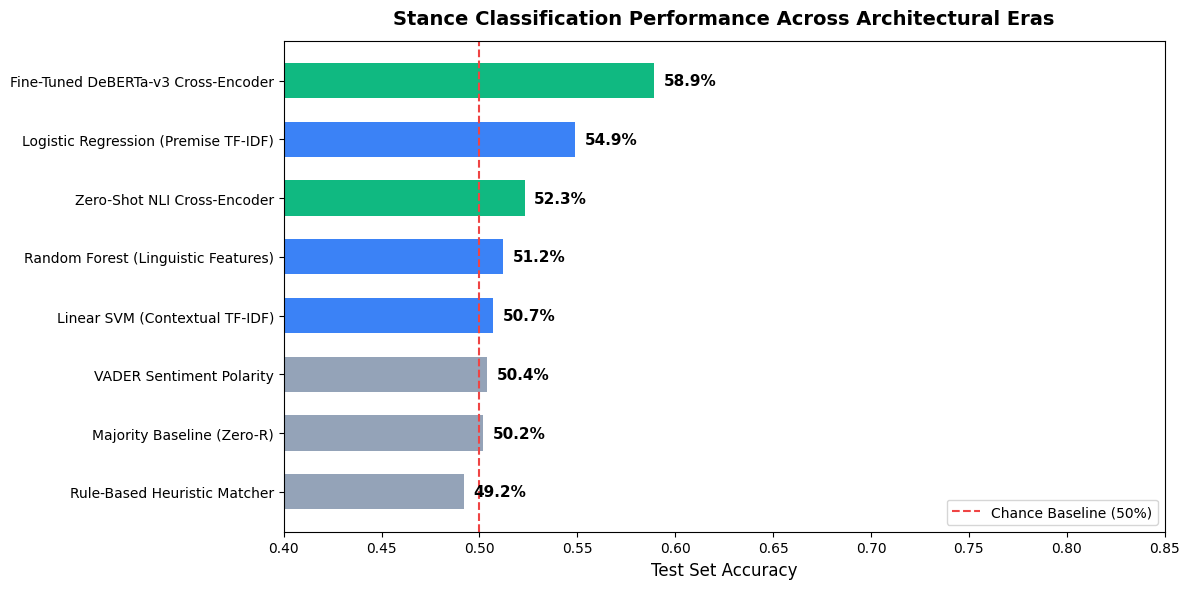

In [19]:
# 7. Comprehensive Paradigm Comparison: Traditional vs. Deep Cross-Encoder
comparison_data = [
    {"Model": "Majority Baseline (Zero-R)", "Accuracy": 0.5020, "Macro F1": 0.3342, "Type": "Baseline"},
    {"Model": "Rule-Based Heuristic Matcher", "Accuracy": 0.4920, "Macro F1": 0.4902, "Type": "Rule-Based"},
    {"Model": "VADER Sentiment Polarity", "Accuracy": 0.5040, "Macro F1": 0.4988, "Type": "Lexicon"},
    {"Model": "Random Forest (Linguistic Features)", "Accuracy": 0.5120, "Macro F1": 0.5117, "Type": "Traditional ML"},
    {"Model": "Linear SVM (Contextual TF-IDF)", "Accuracy": 0.5070, "Macro F1": 0.5067, "Type": "Traditional ML"},
    {"Model": "Logistic Regression (Premise TF-IDF)", "Accuracy": 0.5490, "Macro F1": 0.5490, "Type": "Traditional ML"},
    {"Model": "Zero-Shot NLI Cross-Encoder", "Accuracy": zs_results.accuracy, "Macro F1": zs_results.macro_f1, "Type": "Transformer"},
    {"Model": "Fine-Tuned DeBERTa-v3 Cross-Encoder", "Accuracy": ft_results.accuracy, "Macro F1": ft_results.macro_f1, "Type": "Transformer"},
]
comp_df = pd.DataFrame(comparison_data).sort_values("Accuracy", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
colors = ["#94a3b8" if t in ["Baseline", "Rule-Based", "Lexicon"] else ("#3b82f6" if t == "Traditional ML" else "#10b981") for t in comp_df["Type"]]
bars = ax.barh(comp_df["Model"], comp_df["Accuracy"], color=colors, height=0.6)
ax.axvline(0.50, color="#ef4444", linestyle="--", linewidth=1.5, label="Chance Baseline (50%)")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.1%}", va="center", fontsize=11, fontweight="bold")

ax.set_xlim(0.40, 0.85)
ax.set_xlabel("Test Set Accuracy", fontsize=12)
ax.set_title("Stance Classification Performance Across Architectural Eras", fontsize=14, fontweight="bold", pad=12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [20]:
# 8. Qualitative Error Analysis: Handling Adversarial Quotes & Negations
sample_cases = test_df.sample(5, random_state=42)[["conclusion", "premise_text", "stance"]]
preds, probs = cross_encoder.predict(sample_cases["conclusion"].tolist(), sample_cases["premise_text"].tolist())
sample_cases["Prediction"] = preds
sample_cases["PRO Probability"] = probs.round(4)
sample_cases["Correct"] = sample_cases["stance"] == sample_cases["Prediction"]
sample_cases

,conclusion,premise_text,stance,Prediction,PRO Probability,Correct
521,The Pharoah's of Ancient Egypt were NOT black,There is an awful amount of misinformation out...,PRO,PRO,0.5215,True
737,Should probable cause be used in U.S. schools ...,BEFORE WE BEGIN PLEASE NOTE THAT THE FIRST ROU...,PRO,PRO,0.5254,True
740,Anybody who used performance enhancing drugs i...,The Hall of Fame is merely glorifying the bigg...,CON,CON,0.4969,True
660,Medicines Should Be Made Free,Resolved: Medicines Should Be Made FreeI am Co...,CON,CON,0.3387,True
411,Prescriptive Grammar does more harm than good,"""I challenge my opponent to come up with a 'sl...",CON,CON,0.4044,True
